# How `align_to_template` works: phase correlation, step by step

Goal: two X-ray images of the same part are slightly **shifted** (the part sits a few pixels differently in the frame). We want to slide one image so it lines up with the other.

The idea in one paragraph: a shift in the image becomes a *phase ramp* in the frequency domain. If we divide out the brightness (keep only phase) and go back to the image domain, all the information collapses into **one sharp peak whose position is the shift**.

Steps in this notebook:
1. Make a test pair: a real X-ray image and a copy shifted by a known amount.
2. Do phase correlation by hand (FFT -> cross-power spectrum -> inverse FFT -> find peak) and check it matches `cv2.phaseCorrelate`.
3. Use the shift to align, and see **which sign is correct** (this is the bug in the original function).
4. Sub-pixel shifts and the `max_shift` safety check.
5. The corrected function on a real pair.

template shape (rows, cols): (240, 220)


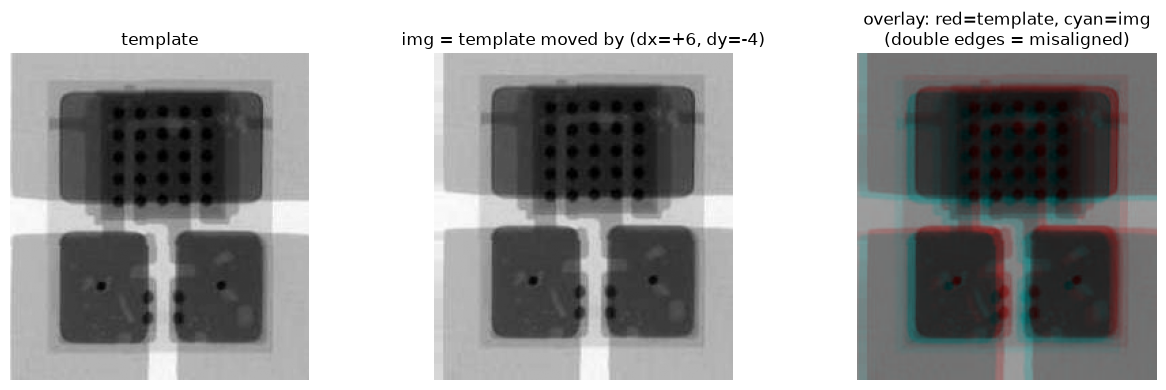

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

XRAY = Path("../data/raw/XRay/XRay")
def read(path): return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE).astype(np.float32)

template = read(XRAY / "FC-GB1" / "XRay_FC-GB1_SAC105_Panel1_LED01_0000TSC.jpg")
print("template shape (rows, cols):", template.shape)

# make a test image: the same picture moved 6 px right and 4 px up (known answer!)
TRUE_DX, TRUE_DY = 6.0, -4.0
M = np.float32([[1, 0, TRUE_DX], [0, 1, TRUE_DY]])
img = cv2.warpAffine(template, M, template.shape[::-1], borderMode=cv2.BORDER_REPLICATE)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(template, cmap="gray"); ax[0].set_title("template")
ax[1].imshow(img, cmap="gray");      ax[1].set_title(f"img = template moved by (dx={TRUE_DX:+.0f}, dy={TRUE_DY:+.0f})")
overlay = np.dstack([template, img, img]) / 255        # red = template, cyan = img
ax[2].imshow(overlay);               ax[2].set_title("overlay: red=template, cyan=img\n(double edges = misaligned)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Step 1 - phase correlation by hand

If `img(x, y) = template(x - dx, y - dy)`, then in the Fourier domain
`F_img = F_template * exp(-i * 2*pi*(u*dx + v*dy))`: the shift only changes the **phase**.

So:
1. `F1 = FFT(template)`, `F2 = FFT(img)`
2. cross-power spectrum `R = F2 * conj(F1) / |F2 * conj(F1)|`. Dividing by the magnitude throws away brightness and keeps pure phase.
3. `r = IFFT(R)` is a sharp spike at `(dy, dx)` (a "delta function"), the shift of `img` relative to `template`.
4. Peak position -> shift. Peaks past half the image size wrap around to negative shifts.

A Hann window (soft fade to zero at the borders) is applied first, because the FFT assumes the image repeats and hard borders create fake edges.

In [2]:
def manual_phase_corr(a, b):
    """Shift of b relative to a, by hand. Returns (dx, dy, correlation surface, spectra)."""
    win = cv2.createHanningWindow(a.shape[::-1], cv2.CV_32F)
    F1 = np.fft.fft2((a - a.mean()) * win)
    F2 = np.fft.fft2((b - b.mean()) * win)
    R = F2 * np.conj(F1)
    R /= np.abs(R) + 1e-12                      # keep phase only
    r = np.real(np.fft.ifft2(R))                 # sharp peak at the shift
    iy, ix = np.unravel_index(np.argmax(r), r.shape)
    h, w = r.shape
    dy = iy - h if iy > h // 2 else iy           # wrap-around -> negative shift
    dx = ix - w if ix > w // 2 else ix
    return dx, dy, np.fft.fftshift(r), (F1, F2, R)

dx_m, dy_m, surface, (F1, F2, R) = manual_phase_corr(template, img)
(dx_cv, dy_cv), response = cv2.phaseCorrelate(template, img, cv2.createHanningWindow(template.shape[::-1], cv2.CV_32F))
print(f"true shift        : dx={TRUE_DX:+.2f}  dy={TRUE_DY:+.2f}")
print(f"manual (integer)  : dx={dx_m:+.2f}  dy={dy_m:+.2f}")
print(f"cv2.phaseCorrelate: dx={dx_cv:+.2f}  dy={dy_cv:+.2f}   (sub-pixel, response={response:.2f})")

true shift        : dx=+6.00  dy=-4.00
manual (integer)  : dx=+6.00  dy=-4.00
cv2.phaseCorrelate: dx=+6.50  dy=-4.00   (sub-pixel, response=0.99)


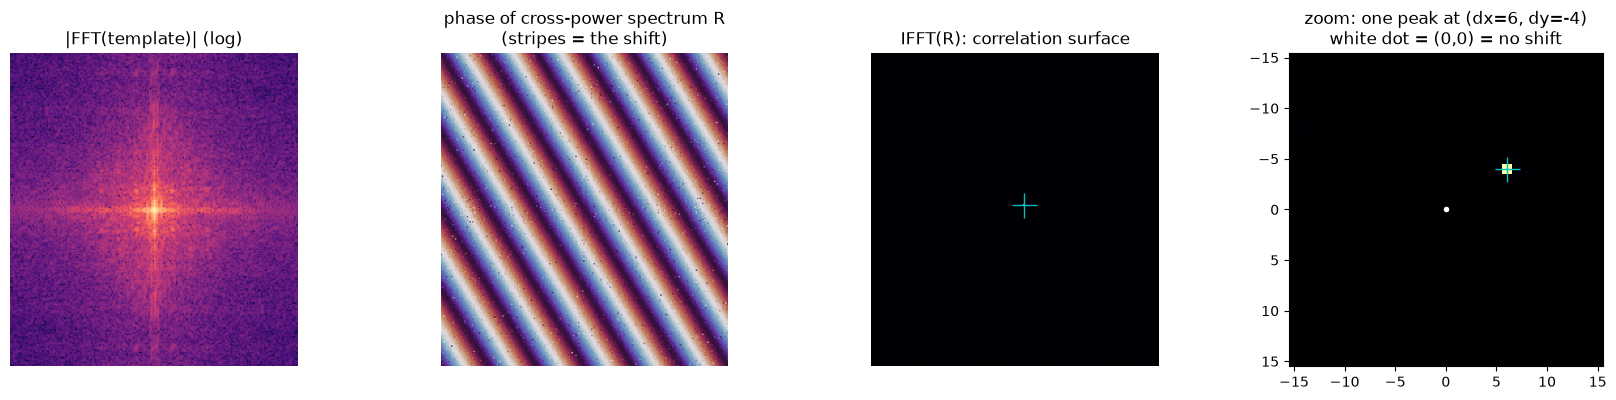

peak height: 0.987 | typical background: 0.00047


In [3]:
h, w = surface.shape
cy, cx = h // 2, w // 2
fig, ax = plt.subplots(1, 4, figsize=(17, 4))

ax[0].imshow(np.log1p(np.abs(np.fft.fftshift(F1))), cmap="magma"); ax[0].set_title("|FFT(template)| (log)")
ax[1].imshow(np.fft.fftshift(np.angle(R)), cmap="twilight");        ax[1].set_title("phase of cross-power spectrum R\n(stripes = the shift)")
ax[2].imshow(surface, cmap="inferno")
ax[2].set_title("IFFT(R): correlation surface"); ax[2].plot(cx + dx_m, cy + dy_m, "c+", ms=18)
ax[3].imshow(surface[cy-15:cy+16, cx-15:cx+16], cmap="inferno", extent=[-15.5, 15.5, 15.5, -15.5])
ax[3].plot(dx_m, dy_m, "c+", ms=18); ax[3].plot(0, 0, "w.", ms=6)
ax[3].set_title(f"zoom: one peak at (dx={dx_m}, dy={dy_m})\nwhite dot = (0,0) = no shift")
for a in ax[:3]: a.axis("off")
plt.tight_layout(); plt.show()
print("peak height:", surface.max().round(3), "| typical background:", np.median(np.abs(surface)).round(5))

Reading the plots: the phase of `R` is a set of regular **stripes**; their direction and spacing encode the shift. The inverse FFT turns those stripes into **one bright dot**. Its offset from the white dot (the centre = zero shift) is `(dx, dy)`.

## Step 2 - use the shift to align: which sign?

`phaseCorrelate(template, img)` tells us how far **img has moved away from template**: `(+6, -4)`.
To bring it back we must move it by the **opposite** amount, `(-dx, -dy)`.

The original code used `+dx, +dy`, which pushes the image *further* away. Compare all three below.

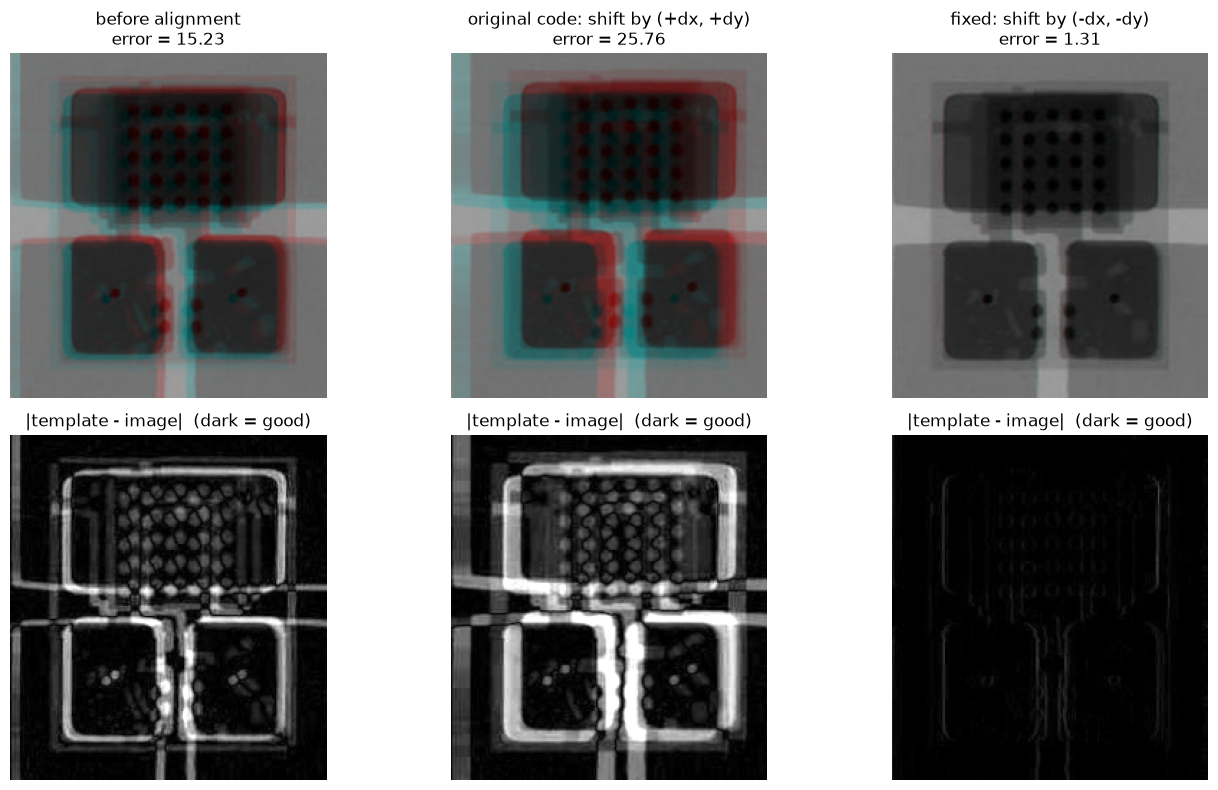

In [4]:
def shift_img(im, dx, dy):
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(im, M, im.shape[::-1], borderMode=cv2.BORDER_REPLICATE)

def err(a, b, m=20):            # mean abs difference, ignoring borders
    return float(np.abs(a - b)[m:-m, m:-m].mean())

cases = {
    "before alignment": img,
    "original code: shift by (+dx, +dy)": shift_img(img, +dx_cv, +dy_cv),
    "fixed: shift by (-dx, -dy)": shift_img(img, -dx_cv, -dy_cv),
}
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for j, (name, im) in enumerate(cases.items()):
    ax[0, j].imshow(np.dstack([template, im, im]) / 255)
    ax[0, j].set_title(f"{name}\nerror = {err(template, im):.2f}")
    ax[1, j].imshow(np.abs(template - im), cmap="gray", vmin=0, vmax=80)
    ax[1, j].set_title("|template - image|  (dark = good)")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

Top row: red = template, cyan = image. Where they overlap exactly the picture is grey/white; offsets show as red and cyan fringes. Bottom row: the pixel difference. The fixed version is almost black (aligned); the original roughly doubles the error.

## Step 3 - sub-pixel shifts and the `max_shift` guard

- The peak is interpolated, so fractional shifts like `3.4` px are estimated, not just whole pixels. In the table below the estimate is within about 0.3-0.5 px in x (it reads slightly high, e.g. 3.73 for 3.4 and 6.5 for 6.0), so treat sub-pixel values as approximate; y is more accurate.
- If the detected shift is bigger than `max_shift` (8 px) the code assumes the match is a false peak and does **not move** the image.

In [5]:
rows = []
win = cv2.createHanningWindow(template.shape[::-1], cv2.CV_32F)
for tdx, tdy in [(3.4, -2.7), (0.5, 0.5), (7.0, 7.0), (20.0, 5.0)]:
    im = shift_img(template, tdx, tdy)
    (fdx, fdy), resp = cv2.phaseCorrelate(template, im, win)
    applied = (0.0, 0.0) if abs(fdx) > 8 or abs(fdy) > 8 else (-fdx, -fdy)
    rows.append((tdx, tdy, fdx, fdy, resp, applied))
print(f"{'true dx,dy':>14} | {'found dx,dy':>14} | response | correction applied")
for tdx, tdy, fdx, fdy, resp, ap in rows:
    print(f"{tdx:6.1f},{tdy:6.1f} | {fdx:6.2f},{fdy:6.2f} | {resp:8.2f} | {ap[0]:+.2f}, {ap[1]:+.2f}" + ("   <- rejected by max_shift" if ap == (0.0, 0.0) else ""))

    true dx,dy |    found dx,dy | response | correction applied
   3.4,  -2.7 |   3.73, -2.76 |     1.03 | -3.73, +2.76
   0.5,   0.5 |   0.68,  0.18 |     0.96 | -0.68, -0.18
   7.0,   7.0 |   7.49,  6.99 |     0.98 | -7.49, -6.99
  20.0,   5.0 |  20.48,  4.99 |     0.94 | +0.00, +0.00   <- rejected by max_shift


The last row shows the trade-off: a true 20 px shift is **found correctly** but exceeds `max_shift`, so it is thrown away and the image stays misaligned. Pick `max_shift` according to how far the parts can really move. The `response` value (peak strength) could also be used to reject weak matches.

## Step 4 - the corrected function on a real pair

Here the template is LED01 and the image is another LED of the same type (a different part, so the voids differ; this is a rougher test than the exact shifted copy above).

synthetic: detected (dy,dx)=(-4.00,+6.50), error after = 1.31
real pair: detected (dy,dx)=(-0.13,+0.96)


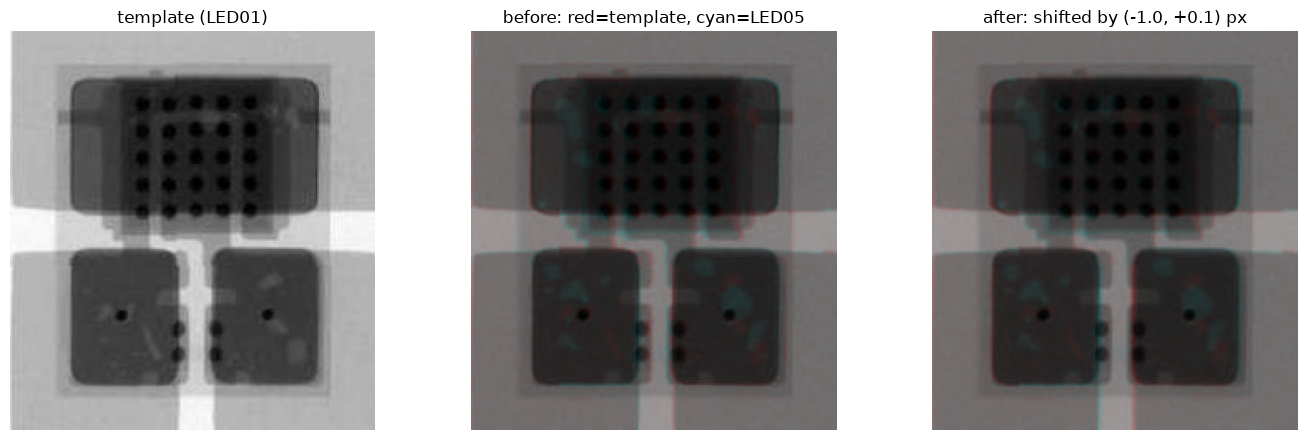

In [6]:
def align_to_template(img, template, max_shift=8):
    """Translation-only alignment via phase correlation (sign fixed). Returns (aligned_img, (dy, dx))."""
    if img.shape != template.shape:
        img = cv2.resize(img, template.shape[::-1])
    win = cv2.createHanningWindow(template.shape[::-1], cv2.CV_32F)
    (dx, dy), _ = cv2.phaseCorrelate(template.astype(np.float32), img.astype(np.float32), win)
    if abs(dy) > max_shift or abs(dx) > max_shift:
        dy, dx = 0.0, 0.0
    M = np.float32([[1, 0, -dx], [0, 1, -dy]])       # move img BACK by the measured shift
    return cv2.warpAffine(img, M, img.shape[::-1], borderMode=cv2.BORDER_REPLICATE), (dy, dx)

# sanity check on the synthetic pair: detected shift is close to the true (6, -4); the leftover error comes from the ~0.5 px x-bias
fixed, (dy_f, dx_f) = align_to_template(img, template)
print(f"synthetic: detected (dy,dx)=({dy_f:+.2f},{dx_f:+.2f}), error after = {err(template, fixed):.2f}")

other = read(XRAY / "FC-GB1" / "XRay_FC-GB1_SAC105_Panel1_LED05_0000TSC.jpg")
aligned, (dy_r, dx_r) = align_to_template(other, template)
print(f"real pair: detected (dy,dx)=({dy_r:+.2f},{dx_r:+.2f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
ax[0].imshow(template, cmap="gray"); ax[0].set_title("template (LED01)")
ax[1].imshow(np.dstack([template, other, other]) / 255); ax[1].set_title("before: red=template, cyan=LED05")
ax[2].imshow(np.dstack([template, aligned, aligned]) / 255); ax[2].set_title(f"after: shifted by ({-dx_r:+.1f}, {-dy_r:+.1f}) px")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Summary

| Step | What happens |
|---|---|
| FFT both images | a shift only changes the phase |
| `R = F2 * conj(F1) / abs(...)` | keep phase, drop brightness |
| inverse FFT | one sharp peak; its position = shift of `img` relative to `template` |
| peak interpolation | sub-pixel `(dx, dy)` |
| `max_shift` check | ignore suspiciously large shifts |
| `warpAffine` with **`-dx, -dy`** | move the image back onto the template |

Limits: translation only (no rotation or scale), and it is only as good as the images share the same structure (package outline, pads). Images with very different content give a weak, unreliable peak.